# Programming Sheet 4: Fisher Discriminant and Perceptron

We train linear classifiers $f(\boldsymbol{x}) = \boldsymbol{w}^\top \boldsymbol{x} + b$, which decide for class $\omega_2$ if $f(\boldsymbol{x}) > 0$ and for class $\omega_1$ otherwise: the Fisher discriminant, a regularized version of it for data with many dimensions, and the perceptron.

**Quiz.** Each exercise asks for one function, with the same name and arguments as in the ISIS quiz for this sheet, which also contains a few short multiple-choice questions. The quiz checks your functions on several inputs and explains with figures what they compute. This week the quiz counts all 100 points of week 4.


In [1]:
import numpy as np
import matplotlib
%matplotlib inline
from matplotlib import pyplot as plt
import sklearn.datasets
import utils

## Data: The Example of the Lecture

Two classes of 100 points each in two dimensions, drawn from Gaussians with the same covariance, elongated and slightly tilted: the example of the lecture figures. As in the previous sheets, the data is stored row by row: `X1` (class $\omega_1$, blue) and `X2` (class $\omega_2$, red) have shape (100, 2). The helpers in `utils.py` draw the figures.


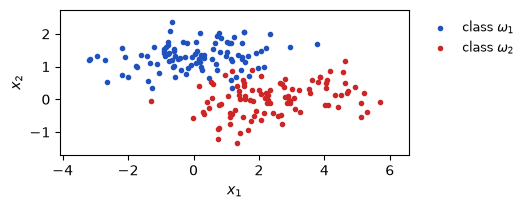

In [2]:
rng = np.random.default_rng(1287)
angle = np.radians(5)
A = np.array(
    [[np.cos(angle), -np.sin(angle)], [np.sin(angle), np.cos(angle)]]
) @ np.diag([1.4, 0.45])
X1 = rng.normal(size=(100, 2)) @ A.T + [0, 1.2]
X2 = rng.normal(size=(100, 2)) @ A.T + [2.2, 0]
utils.plot_classes(X1, X2)

## Exercise 1: Fisher Discriminant

The Fisher discriminant projects the data on the direction

$$
\boldsymbol{w} \propto S_W^{-1}(\boldsymbol{m}_2 - \boldsymbol{m}_1), \qquad
S_W = S_1 + S_2, \qquad
S_j = \sum_{\boldsymbol{x} \in X_j} (\boldsymbol{x} - \boldsymbol{m}_j)(\boldsymbol{x} - \boldsymbol{m}_j)^\top, \quad j \in \{1, 2\},
$$

where the sum runs over the points of class $j$, the rows of `X1` or `X2`, $\boldsymbol{m}_j$ is their mean and $S_j$ their scatter matrix. The analysis gives only the direction; as bias we take the threshold halfway between the projected means,

$$
b = -\tfrac12\, \boldsymbol{w}^\top(\boldsymbol{m}_1 + \boldsymbol{m}_2).
$$

The scatter matrix of the points of one class is given in `utils.py`:

```python
def scatter(X):
    # scatter matrix of the rows of X: a sum over the points
    Xc = X - X.mean(axis=0)
    return Xc.T @ Xc
```


In [3]:
from utils import scatter

For the linear system, use `np.linalg.solve(S_W, m2 - m1)` rather than computing the inverse.

- **Implement `fisher(X1, X2)`**, which returns the pair `(w, b)`: the Fisher direction `w` with unit length, an array of shape (d,), and the bias `b` above, a number. `w` points from class 1 to class 2, $\boldsymbol{w}^\top(\boldsymbol{m}_2 - \boldsymbol{m}_1) > 0$, so that the classifier decides for $\omega_2$ if $\boldsymbol{w}^\top\boldsymbol{x} + b > 0$.


In [4]:
def fisher(X1: np.ndarray, X2: np.ndarray) -> tuple[np.ndarray, float]:
    """Compute Fisher's linear discriminant for two classes.

    Args:
        - X1: Data points of class 1, shape (n1, d).
        - X2: Data points of class 2, shape (n2, d).

    Returns:
        - w: Normalized Fisher direction, shape (d,).
        - b: Bias defining decision boundary.
    """
    # Compute within-class scatter matrix
    S_W = scatter(X1) + scatter(X2)

    # Compute means
    m1, m2 = X1.mean(axis=0), X2.mean(axis=0)

    # Calculate w
    w = np.linalg.solve(S_W, m2 - m1)

    # Normalize w
    w = w / np.linalg.norm(w)

    # Calculate bias
    b = -0.5 * np.dot(w, m1 + m2)

    return w, b

We compare it with the mean separation of the lecture, the direction $\boldsymbol{w} \propto \boldsymbol{m}_2 - \boldsymbol{m}_1$ with the same rule for the bias, and compute their errors: the fraction of the points of each class on the wrong side of the boundary, averaged over the two classes.


mean separation: error 13.0%
Fisher:          error 4.5%


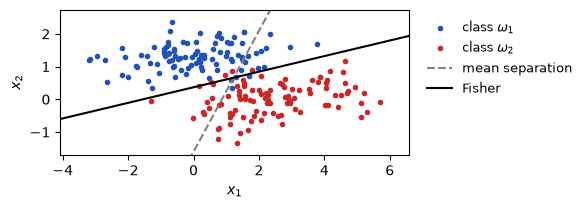

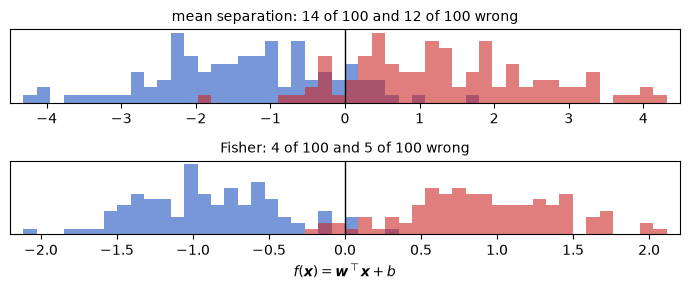

In [5]:
def mean_separation(X1, X2):
    m1, m2 = X1.mean(axis=0), X2.mean(axis=0)
    w = (m2 - m1) / np.linalg.norm(m2 - m1)
    return w, -w @ (m1 + m2) / 2


def error(X1, X2, w, b):
    # the fraction of each class on the wrong side of the boundary,
    # averaged over the two classes
    return (np.mean(X1 @ w + b > 0) + np.mean(X2 @ w + b <= 0)) / 2


w_m, b_m = mean_separation(X1, X2)
w_f, b_f = fisher(X1, X2)
print(f"mean separation: error {error(X1, X2, w_m, b_m):.1%}")
print(f"Fisher:          error {error(X1, X2, w_f, b_f):.1%}")

utils.plot_classes(X1, X2, [(w_m, b_m, "mean separation"), (w_f, b_f, "Fisher")])
utils.plot_projections(
    [(X1, X2, w_m, b_m, "mean separation"), (X1, X2, w_f, b_f, "Fisher")]
)

Along the difference of the means, the projected classes overlap strongly. Fisher turns the direction towards the short axis of the classes, where they are narrow: the projected means are closer together, but the classes overlap much less.

### Measuring in Other Units

The two features are measured in some units. What if we measure one of them in a unit half as large, i.e. multiply it by 2? We train both classifiers on the rescaled data and draw their boundaries in the original coordinates: a boundary $\boldsymbol{w}^\top D \boldsymbol{x} + b = 0$ for the rescaled points $D\boldsymbol{x}$ is the line with normal $D\boldsymbol{w}$.


original units  mean separation  13.0%   Fisher   4.5%
x1 times 2      mean separation  19.0%   Fisher   4.5%
x2 times 2      mean separation   6.5%   Fisher   4.5%


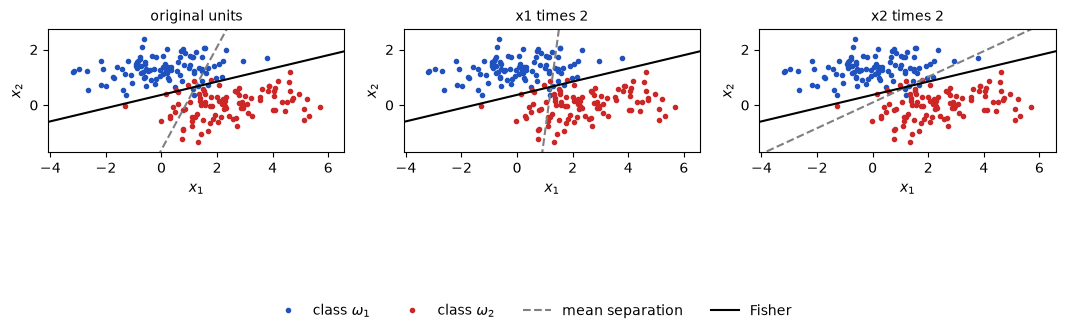

In [6]:
units = [
    (np.diag([1.0, 1.0]), "original units"),
    (np.diag([2.0, 1.0]), "x1 times 2"),
    (np.diag([1.0, 2.0]), "x2 times 2"),
]
fig, axes = plt.subplots(1, 3, figsize=(13, 4.2))
for ax, (D, name) in zip(axes, units):
    Y1, Y2 = X1 @ D, X2 @ D
    w_mD, b_mD = mean_separation(Y1, Y2)
    w_fD, b_fD = fisher(Y1, Y2)
    print(
        f"{name:15s} mean separation {error(Y1, Y2, w_mD, b_mD):6.1%}"
        f"   Fisher {error(Y1, Y2, w_fD, b_fD):6.1%}"
    )
    utils.plot_classes(
        X1,
        X2,
        [(D @ w_mD, b_mD, "mean separation"), (D @ w_fD, b_fD, "Fisher")],
        title=name,
        ax=ax,
        legend=False,
    )
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=4, frameon=False)
fig.subplots_adjust(bottom=0.25)
plt.show()

The Fisher boundary is the same line in all three cases, while the boundary of the mean separation moves with the unit, and so does its error.

**Question.** Why does the unit of a feature not affect the Fisher discriminant? (One of the multiple-choice questions of the quiz asks about this.)

## Exercise 2: Fisher Discriminant with Few Training Points

We return to the faces of Sheet 3 (_Labeled Faces in the Wild_) and separate the photos of two persons: George W. Bush (class $\omega_1$) and Luiz Inácio Lula da Silva (class $\omega_2$), who wears a beard. We use a lower resolution than in Sheet 3, 18 × 14 = 252 pixels, and standardize each image on its own as there. The dataset has 530 images of Bush, but only 48 of Lula: we train with 200 images of Bush and 36 of Lula and test on the remaining ones. Because the test set then contains many more images of Bush, the function `error` from Exercise 1 averages the error rates of the two classes, so that both count equally.


18 x 14 pixels, 530 images of Bush, 48 of Lula


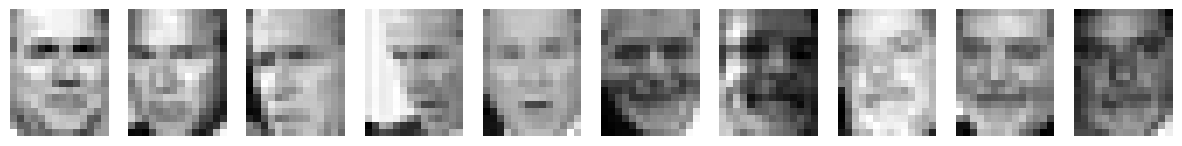

rank of S_W: 234 of 252


In [7]:
lfw = sklearn.datasets.fetch_lfw_people(resize=0.15, min_faces_per_person=40)
shape = lfw.images.shape[1:]
faces = lfw.images.reshape(len(lfw.images), -1).astype(float)
mean = faces.mean(axis=1, keepdims=True)  # one per image
std = faces.std(axis=1, keepdims=True)
faces = (faces - mean) / std
names = list(lfw.target_names)
bush = faces[lfw.target == names.index("George W Bush")]
lula = faces[lfw.target == names.index("Luiz Inacio Lula da Silva")]
print(
    f"{shape[0]} x {shape[1]} pixels, "
    f"{len(bush)} images of Bush, {len(lula)} of Lula"
)
utils.render_faces(np.concatenate([bush[:5], lula[:5]]), shape)


def split(seed, n1=200, n2=36):
    # random images of each person for training, the rest for testing
    rng = np.random.default_rng(seed)
    i1 = rng.permutation(len(bush))
    i2 = rng.permutation(len(lula))
    return (bush[i1[:n1]], lula[i2[:n2]], bush[i1[n1:]], lula[i2[n2:]])


X1_train, X2_train, X1_test, X2_test = split(18)
S_W = scatter(X1_train) + scatter(X2_train)
print(f"rank of S_W: {np.linalg.matrix_rank(S_W)} of {S_W.shape[0]}")

The within-class scatter matrix is not invertible: $S_1$ is a sum over 200 images around their mean and has rank at most 199, $S_2$ at most 35, so $S_W$ has rank at most 234 < 252. In the directions it misses, the training images of a class do not vary at all, and in its directions of small variance it mostly describes the noise of this particular sample, which $S_W^{-1}$ would amplify. The lecture proposes to _regularize_ $S_W$: we replace it by

$$
\widetilde S_W = (1 - \gamma)\, S_W + \gamma\, \nu I, \qquad \nu = \frac{\operatorname{tr} S_W}{d}, \qquad 0 \le \gamma \le 1,
$$

a mix of $S_W$ and a multiple of the identity; $\nu$, the mean of the diagonal entries of $S_W$, gives both parts the same scale. For $\gamma > 0$, $\widetilde S_W$ is invertible. For $\gamma = 0$ we get the Fisher discriminant; for $\gamma = 1$, $\widetilde S_W = \nu I$ and $\boldsymbol{w} \propto \boldsymbol{m}_2 - \boldsymbol{m}_1$: the mean separation.

- **Implement `fisher_regularized(X1, X2, gamma)`**, which returns the pair `(w, b)` as in Exercise 1, with $\widetilde S_W$ in place of $S_W$.


In [8]:
def fisher_regularized(
    X1: np.ndarray, X2: np.ndarray, gamma: float
) -> tuple[np.ndarray, float]:
    """
    Compute regularized Fisher's linear discriminant for two classes.

    Args:
        X1: Data points of class 1, shape (n1, d).
        X2: Data points of class 2, shape (n2, d).
        gamma: Regularization parameter between 0 and 1.

    Returns:
        w: Normalized Fisher direction, shape (d,).
        b: Bias defining the decision boundary.
    """
    # Compute within-class scatter matrix
    S_W = scatter(X1) + scatter(X2)

    # Regularize scatter matrix
    d = X1.shape[1]
    nu = np.trace(S_W) / d
    S_W = (1 - gamma) * S_W + gamma * nu * np.eye(d)

    # Compute means
    m1, m2 = X1.mean(axis=0), X2.mean(axis=0)

    # Calculate w
    w = np.linalg.solve(S_W, m2 - m1)

    # Normalize w
    w = w / np.linalg.norm(w)

    # Calculate bias
    b = -0.5 * np.dot(w, m1 + m2)

    return w, b

We train for values of $\gamma$ between $10^{-3}$ and 1 and compute the errors on the training and on the test images. With only 12 test images of Lula, the curves of a single choice of the training images are noisy, so we average over 200 random choices (this takes a few seconds).


test error 15.9% for gamma = 0.001, 6.9% for gamma = 0.32, 12.5% for gamma = 1


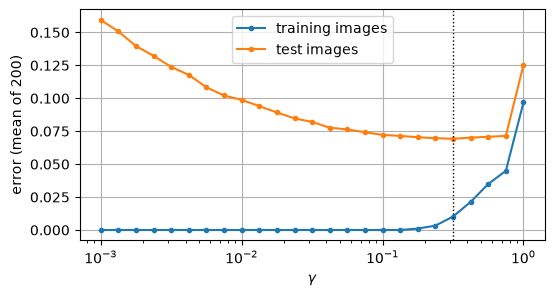

In [9]:
gammas = np.logspace(-3, 0, 25)
train = np.zeros((200, len(gammas)))
test = np.zeros((200, len(gammas)))
for seed in range(200):
    A_train, B_train, A_test, B_test = split(seed)
    for i, gamma in enumerate(gammas):
        w, b = fisher_regularized(A_train, B_train, gamma)
        train[seed, i] = error(A_train, B_train, w, b)
        test[seed, i] = error(A_test, B_test, w, b)
train, test = train.mean(axis=0), test.mean(axis=0)
best = gammas[np.argmin(test)]
print(
    f"test error {test[0]:.1%} for gamma = 0.001, "
    f"{test.min():.1%} for gamma = {best:.2f}, "
    f"{test[-1]:.1%} for gamma = 1"
)

plt.figure(figsize=(6, 3))
plt.semilogx(gammas, train, ".-", label="training images")
plt.semilogx(gammas, test, ".-", label="test images")
plt.axvline(best, color="k", lw=1, ls=":")
plt.xlabel(r"$\gamma$")
plt.ylabel("error (mean of 200)")
plt.legend()
plt.grid(True)
plt.show()

The training error grows with $\gamma$: the regularization keeps the classifier from adapting to the training images. The test error first falls, reaches its minimum (dotted) where the training error has already begun to rise, and grows again towards the mean separation at $\gamma = 1$. The minimum is broad: between about 0.2 and 0.75 the test error hardly changes, and which $\gamma$ in this range comes out best depends on the random choices.

**Question.** How can a larger training error go along with a smaller test error? (One of the multiple-choice questions of the quiz asks about this.)

For the training images from above, we look at $\boldsymbol{w}$ for little regularization, for the best $\gamma$ and for the mean separation (top row), and at how it decides for two test images (below), one of each person, that are on the wrong side for $\gamma = 0.001$ and for $\gamma = 1$, and on the right side only for the best $\gamma$. With the midpoint $\boldsymbol{m} = \frac12(\boldsymbol{m}_1 + \boldsymbol{m}_2)$ of the class means, $b = -\boldsymbol{w}^\top\boldsymbol{m}$ and

$$
f(\boldsymbol{x}) = \boldsymbol{w}^\top(\boldsymbol{x} - \boldsymbol{m}) = \sum_{i=1}^d w_i\, (x_i - m_i),
$$

a sum of one term per pixel. The images below show these terms (red: towards Lula, blue: towards Bush), the titles their sum, split into the terms on the border of the image, the outer two pixels outside the dashed line, and those inside.


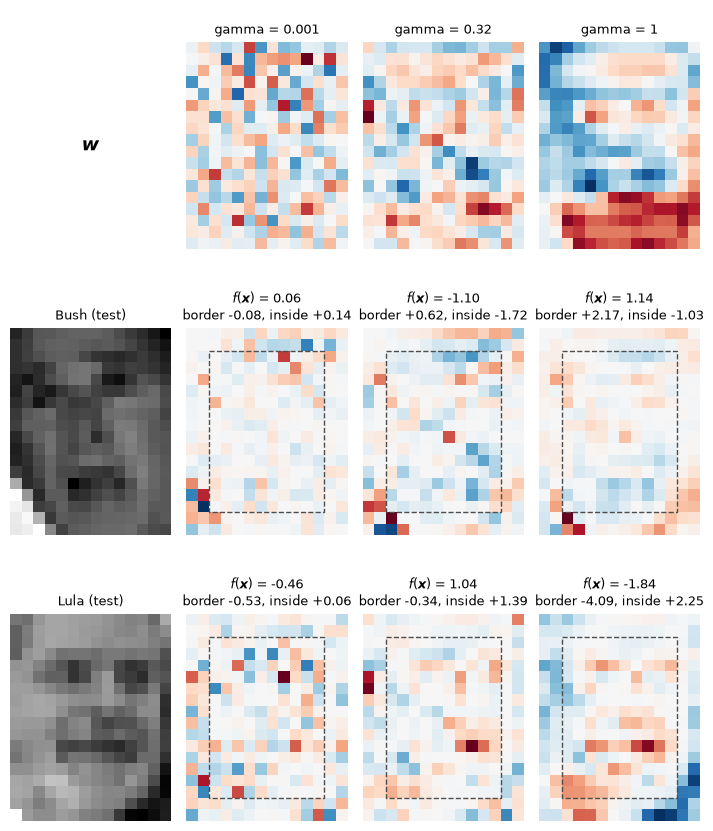

In [10]:
cases = [(0.001, "gamma = 0.001"), (best, f"gamma = {best:.2f}"), (1.0, "gamma = 1")]
fits = [fisher_regularized(X1_train, X2_train, gamma) for gamma, _ in cases]
m = (X1_train.mean(axis=0) + X2_train.mean(axis=0)) / 2
# two test images that only the best gamma classifies correctly
examples = [X1_test[50], X2_test[3]]
utils.plot_contributions(
    fits,
    [name for _, name in cases],
    examples,
    ["Bush (test)", "Lula (test)"],
    shape,
    m,
)

The projections of all training and test images for the same three values of $\gamma$. Each person's histogram has the same area, although there are many more images of Bush; the titles give the numbers.


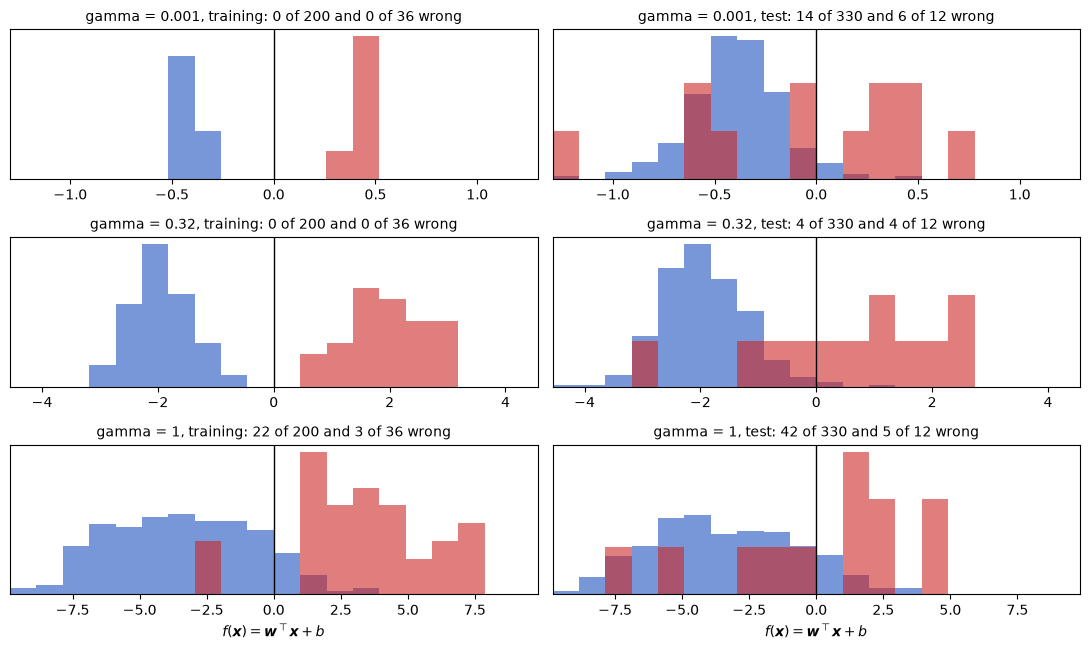

In [11]:
panels = []
for (w, b), (_, name) in zip(fits, cases):
    panels.append((X1_train, X2_train, w, b, name + ", training"))
    panels.append((X1_test, X2_test, w, b, name + ", test"))
utils.plot_projections(panels, ncols=2, bins=10)

With little regularization, all training images of a person fall on nearly the same value: $\boldsymbol{w}$ uses directions in which the 236 training images hardly vary, the _data piling_ of the lecture. It looks like noise, its terms for a test image are small and of both signs, and many test images fall on the wrong side. With $\gamma = 1$, $\boldsymbol{w}$ is the difference of the two mean faces, with a red band over chin and jaw, where Lula has his beard; but it ignores how the pixels vary together, and more images fall on the wrong side, even among the training images. At the best $\gamma$, $\boldsymbol{w}$ is still grainy, but the two test images show what it gains. For $\gamma = 1$, the terms inside the face point to the right person, but those on the border of the image, where background, hair and the light of the particular photo show, are larger and point to the wrong one. The mean faces differ on the border about as much as inside, but there the photos of each person vary about twice as much (the diagonal of $S_W$). The mean separation ignores this; with the best $\gamma$ the classifier takes it into account, and the border terms add up to much less.

## Exercise 3: Perceptron

The perceptron of the lecture trains the weights $\boldsymbol{w}$ and the bias $b$ of a linear classifier $f(\boldsymbol{x}) = \boldsymbol{w}^\top\boldsymbol{x} + b$ on points with labels $t_k = +1$ for class $\omega_2$ and $t_k = -1$ for class $\omega_1$. It visits the points $\boldsymbol{x}_1, \dots, \boldsymbol{x}_N$ in the given order, and whenever a point lies on the wrong side of the boundary or on it, $t_k(\boldsymbol{w}^\top\boldsymbol{x}_k + b) \le 0$, it updates

$$
\boldsymbol{w} \leftarrow \boldsymbol{w} + \eta\, t_k \boldsymbol{x}_k, \qquad b \leftarrow b + \eta\, t_k,
$$

with the learning rate $\eta$. One pass over all points is an _epoch_. The perceptron stops after an epoch without updates, or after a maximal number of epochs.

- **Implement `perceptron(X, t, w, b, eta, max_epochs)`** with the arguments
  - `X`: the points $\boldsymbol{x}_1, \dots, \boldsymbol{x}_N$, one per row, an array of shape (N, d),
  - `t`: their labels $t_k = \pm 1$, an array of shape (N,),
  - `w`, `b`: the start values of the weights, an array of shape (d,), and of the bias, a number,
  - `eta`: the learning rate $\eta$,
  - `max_epochs`: the maximal number of epochs.

  It returns the triple `(w, b, n_updates)`: the weights and the bias when the perceptron stops, and the number of updates over all epochs.


In [13]:
def perceptron(
    X: np.ndarray, t: np.ndarray, w: np.ndarray, b: float, eta: float, max_epochs: int
) -> tuple[np.ndarray, float, int]:
    """
    Train a perceptron for binary classification.

    Args:
        X: Data points, shape (N, d).
        t: Class labels (-1 or +1), shape (N,).
        w: Initial weights, shape (d,).
        b: Initial bias.
        eta: Learning rate.
        max_epochs: Maximum number of training epochs.

    Returns:
        w: Updated weights, shape (d,).
        b: Updated bias.
        n_updates: Total number of weight updates.
    """
    # Initialize variables
    w = w.astype(float).copy()
    n_updates = 0

    # Iterate over epochs
    for epoch in range(max_epochs):
        updated = False

        # Iterate over data points
        for x, label in zip(X, t):

            # Check if point is misclassified
            if label * (np.dot(w, x) + b) <= 0:

                # Update weights and bias
                w = w + eta * label * x
                b = b + eta * label

                n_updates += 1
                updated = True

        # Stop if no updates were made
        if not updated:
            break

    return w, b, n_updates

The example of the lecture: nine points, start $\boldsymbol{w} = (-1, 1)^\top$, $b = 0$ and $\eta = 0.5$. We draw the boundary at the start and after each epoch, with rings around the points on the wrong side, and then let the perceptron run until it stops.


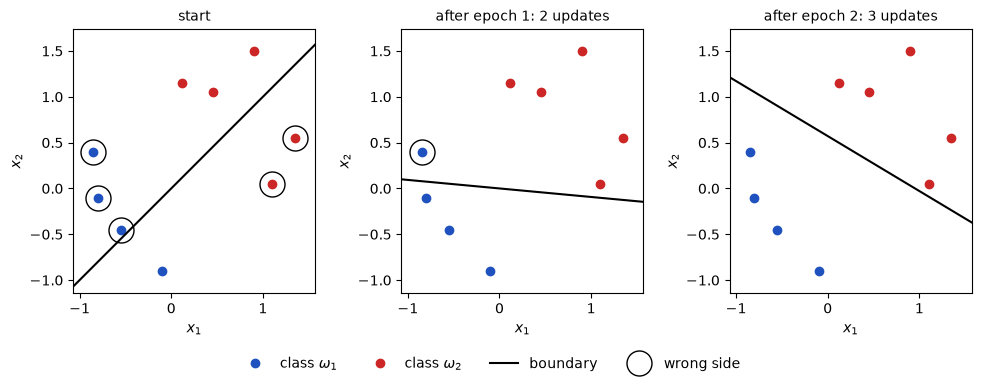

w = [0.525 0.875], b = -0.5, 3 updates
closest point at distance 0.12 from the boundary


In [14]:
P2 = np.array([(0.9, 1.5), (0.45, 1.05), (1.35, 0.55), (0.12, 1.15), (1.1, 0.05)])
P1 = np.array([(-0.85, 0.4), (-0.8, -0.1), (-0.55, -0.45), (-0.1, -0.9)])
P = np.concatenate([P2, P1])
t = np.concatenate([np.ones(len(P2)), -np.ones(len(P1))])

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, epochs in zip(axes, [0, 1, 2]):
    w, b, n_updates = perceptron(P, t, np.array([-1.0, 1.0]), 0.0, 0.5, epochs)
    title = "start" if epochs == 0 else (f"after epoch {epochs}: {n_updates} updates")
    utils.plot_classes(
        P1,
        P2,
        [(w, b, "boundary")],
        title=title,
        ax=ax,
        legend=False,
        mark_errors=True,
        ms=6,
    )
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=4, frameon=False)
fig.subplots_adjust(bottom=0.22)
plt.show()

w, b, n_updates = perceptron(P, t, np.array([-1.0, 1.0]), 0.0, 0.5, 100)
margin = np.min(t * (P @ w + b)) / np.linalg.norm(w)
print(f"w = {w}, b = {b}, {n_updates} updates")
print(f"closest point at distance {margin:.2f} from the boundary")

After the second epoch all points are on the right side, the third epoch changes nothing, and the perceptron stops after three updates, as on the slides of the lecture, with a boundary that passes close to a point.

**Question.** What does the stopping rule of the perceptron guarantee about the boundary it returns, and what not? (One of the multiple-choice questions of the quiz asks about this.)

### Data That Is Not Separable

The two classes of Exercise 1 overlap: no line separates them. We run the perceptron on them, in a random order of the points, from $\boldsymbol{w} = \boldsymbol{0}$, $b = 0$ with $\eta = 0.1$, and count the errors after each epoch.


275 updates in 30 epochs


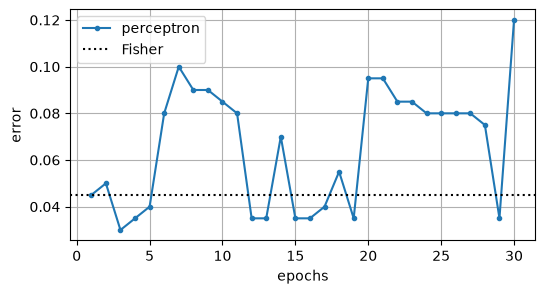

In [15]:
X = np.concatenate([X1, X2])
t = np.concatenate([-np.ones(len(X1)), np.ones(len(X2))])
order = np.random.default_rng(0).permutation(len(X))
X, t = X[order], t[order]

errors = []
for epochs in range(1, 31):
    w, b, n_updates = perceptron(X, t, np.zeros(2), 0.0, 0.1, epochs)
    errors.append(error(X1, X2, w, b))
print(f"{n_updates} updates in 30 epochs")

plt.figure(figsize=(6, 3))
plt.plot(range(1, 31), errors, ".-", label="perceptron")
plt.axhline(error(X1, X2, w_f, b_f), color="k", ls=":", label="Fisher")
plt.xlabel("epochs")
plt.ylabel("error")
plt.legend()
plt.grid(True)
plt.show()

Some point is always on the wrong side, so the perceptron never stops, and its error jumps from epoch to epoch: every update corrects one point and may move others to the wrong side. Fisher's error (dotted) needs no iteration at all.
